# Лабораторная работа 1

1) Классификация данных методом k ближайших соседей ( kNN)

2) Классификация данных методом опорных векторов (SVM)

3) Построение softmax-классификатора

Вариант 1: задания 1 и 2 на наборе данных CIFAR-10

Вариант 2: задания 1 и 2 на наборе данных MNIST

Вариант 3: задания 1 и 3 на наборе данных CIFAR-10

Вариант 4: задания 1 и 3 на наборе данных MNIST

Лабораторные работы можно выполнять с использованием сервиса Google Colaboratory (https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) или на локальном компьютере.

## 1. Классификация данных методом k ближайших соседей ( kNN)

In [17]:
!pip install numpy
!pip install matplotlib
!pip install scikit-learn

In [18]:
import random
import numpy as np
import matplotlib.pyplot as plt
#from scripts.data_utils import load_CIFAR10



%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

1.1 Скачайте данные в соответсвии с заданием.

CIFAR-10 по ссылке https://www.cs.toronto.edu/~kriz/cifar.html
или используйте  команду !bash get_datasets.sh (google colab, local ubuntu)

MNIST
sklearn.datasets import load_digits
digits = load_digits()

In [19]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()

In [20]:
#cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X = digits.data
Y = digits.target

X_train, X_test, Y_train, Y_test = train_test_split(X, Y)
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', Y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', Y_test.shape)

Training data shape:  (1347, 64)
Training labels shape:  (1347,)
Test data shape:  (450, 64)
Test labels shape:  (450,)


1.2 Выведите несколько примеров изображений из обучающей выборки для каждого класса.



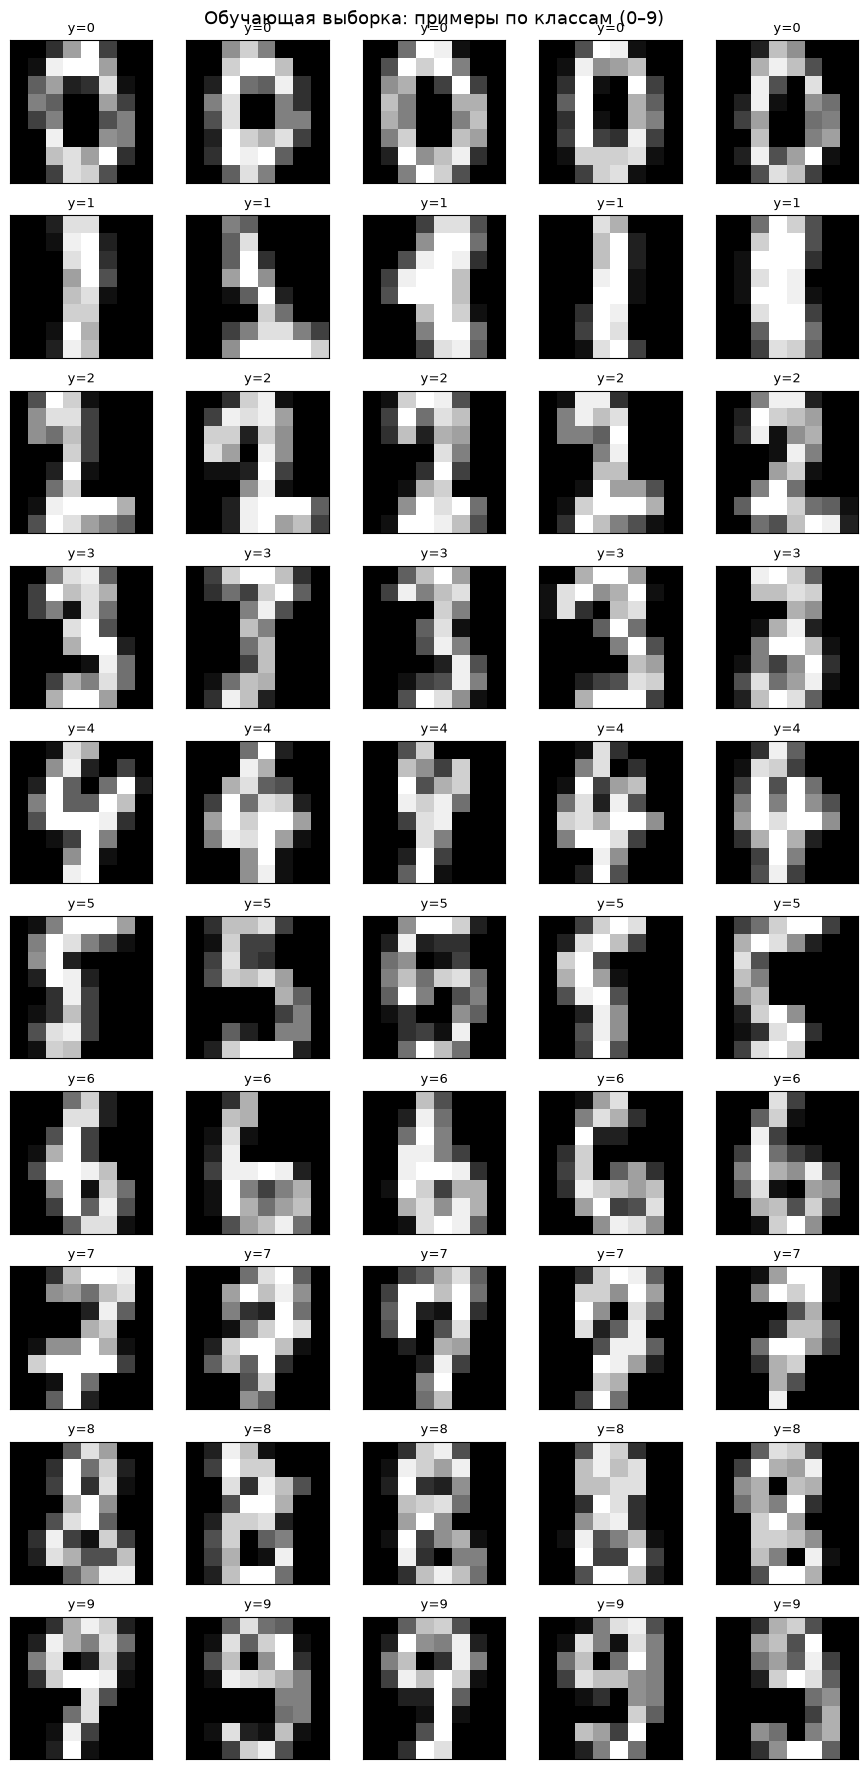

In [21]:
import numpy as np
import matplotlib.pyplot as plt

classes = np.unique(Y_train)
num_classes = len(classes)
samples_per_class = 5

np.random.seed(42)  

fig, axes = plt.subplots(num_classes, samples_per_class,
                         figsize=(samples_per_class * 1.8, num_classes * 1.8))

for cls_idx, cls in enumerate(classes):
    idxs = np.where(Y_train == cls)[0]
    chosen = np.random.choice(idxs, samples_per_class, replace=False)

    for i, idx in enumerate(chosen):
        ax = axes[cls_idx, i]
        ax.imshow(X_train[idx].reshape(8, 8), cmap='gray')
        ax.set_title(f'y={cls}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle('Обучающая выборка: примеры по классам (0–9)', fontsize=13)
plt.tight_layout()
plt.show()

1.3 Разделите данные на обучающу и тестовую выборки (X_train, y_train, X_test, y_test). Преобразуйте каждое изображение в одномерный массив.

1.4 Напишите реализацию классификатора в скрипте /classifiers/k_nearest_neighbor.py и обучите его на сформированной выборке.

In [22]:
from scripts.classifiers.k_nearest_neighbor import KNearestNeighbor

classifier = KNearestNeighbor()
classifier.train(X_train, Y_train)

1.5 Выполните классификацию на тестовой выборке




In [23]:
Y_pred = classifier.predict(X_test, k=1)

1.6 Визуализируйте матрицу расстояний для каждого изображения из тестовой выборки до изображений из обучающей выборки.


Форма матрицы расстояний: (450, 1347)


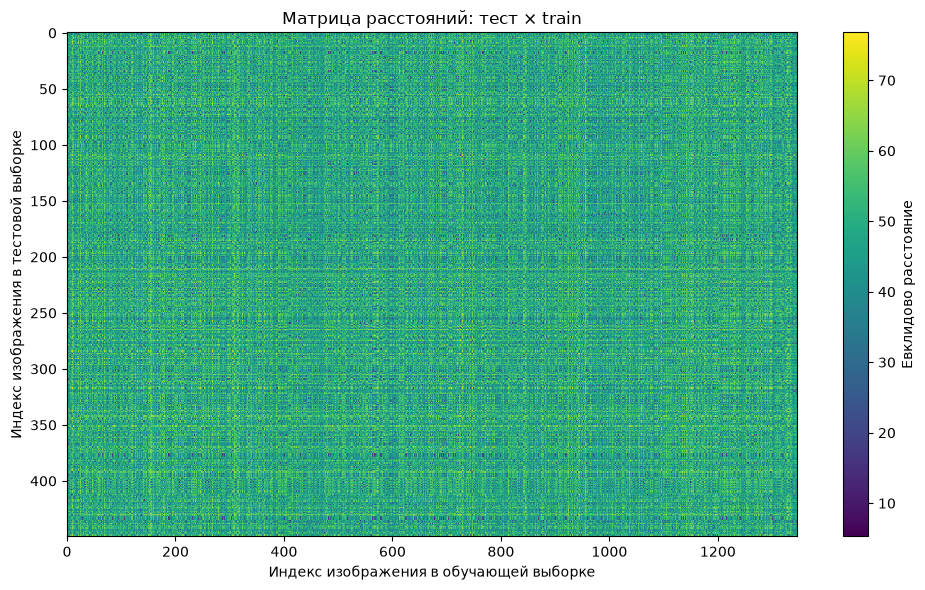

In [24]:
# Вычисляем матрицу расстояний: shape (num_test, num_train)
dists = classifier.compute_distances(X_test)
print('Форма матрицы расстояний:', dists.shape)

plt.figure(figsize=(10, 6))
plt.imshow(dists, aspect='auto', cmap='viridis')
plt.colorbar(label='Евклидово расстояние')
plt.xlabel('Индекс изображения в обучающей выборке')
plt.ylabel('Индекс изображения в тестовой выборке')
plt.title('Матрица расстояний: тест × train')
plt.tight_layout()
plt.show()


1.7 Посчитайте долю правильно классифицированных изображений из тестовой выборки.


In [25]:
accuracy = np.mean(Y_pred == Y_test)
print(f'Accuracy: {accuracy:.4f}')
print(f'Правильно: {np.sum(Y_pred == Y_test)} из {len(Y_test)}')

Accuracy: 0.9844
Правильно: 443 из 450


1.8 Постройте график зависимости доли правильно классифицированных изображений от числа соседей, используемых при классификации.

k= 1 → accuracy: 0.9844
k= 2 → accuracy: 0.9889
k= 3 → accuracy: 0.9844
k= 4 → accuracy: 0.9822
k= 5 → accuracy: 0.9844
k= 6 → accuracy: 0.9822
k= 7 → accuracy: 0.9844
k= 8 → accuracy: 0.9822
k= 9 → accuracy: 0.9844
k=10 → accuracy: 0.9844
k=11 → accuracy: 0.9889
k=12 → accuracy: 0.9778
k=13 → accuracy: 0.9800
k=14 → accuracy: 0.9800
k=15 → accuracy: 0.9822
k=16 → accuracy: 0.9800
k=17 → accuracy: 0.9778
k=18 → accuracy: 0.9756
k=19 → accuracy: 0.9756
k=20 → accuracy: 0.9733


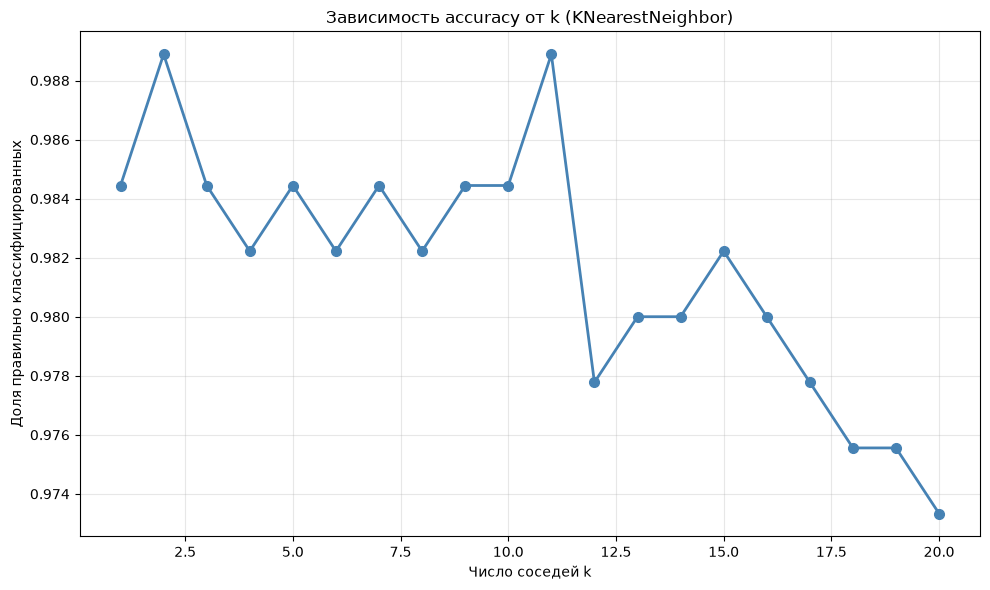

In [26]:
# Диапазон значений k
k_values = range(1, 21)
accuracies = []

for k in k_values:
    Y_pred = classifier.predict(X_test, k=k)
    acc = np.mean(Y_pred == Y_test)
    accuracies.append(acc)
    print(f'k={k:2d} → accuracy: {acc:.4f}')

# График
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, 'o-', color='steelblue',
         linewidth=2, markersize=7)
plt.xlabel('Число соседей k')
plt.ylabel('Доля правильно классифицированных')
plt.title('Зависимость accuracy от k (KNearestNeighbor)')
plt.grid(True, alpha=0.3)



plt.tight_layout()
plt.show()



1.9 Выберите лучшее значение параметра k на основе кросс-валидации.


In [27]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
k_values = range(1, 21)

cv_accuracies = {k: [] for k in k_values}

for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train[train_idx], X_train[val_idx]
    Y_tr, Y_val = Y_train[train_idx], Y_train[val_idx]

    clf = KNearestNeighbor()
    clf.train(X_tr, Y_tr)

    for k in k_values:
        Y_val_pred = clf.predict(X_val, k=k)
        cv_accuracies[k].append(np.mean(Y_val_pred == Y_val))

# Средняя точность по фолдам для каждого k
mean_cv = {k: np.mean(v) for k, v in cv_accuracies.items()}
std_cv  = {k: np.std(v)  for k, v in cv_accuracies.items()}

best_k = max(mean_cv, key=mean_cv.get)
print(f'Лучшее k по кросс-валидации: {best_k} '
      f'(accuracy = {mean_cv[best_k]:.4f} ± {std_cv[best_k]:.4f})')


Лучшее k по кросс-валидации: 1 (accuracy = 0.9859 ± 0.0068)



1.10 Переобучите и протестируйте классификатор с использованием выбранного значения k.



In [28]:
classifier = KNearestNeighbor()
classifier.train(X_train, Y_train)

best_k = 1
Y_pred = classifier.predict(X_test, k=best_k)

accuracy = np.mean(Y_pred == Y_test)
n_correct = np.sum(Y_pred == Y_test)
n_total = len(Y_test)

print(f'Лучшее k: {best_k}')
print(f'Accuracy на тестовой выборке: {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'Правильно: {n_correct} из {n_total}')
print(f'Ошибок: {n_total - n_correct}')

Лучшее k: 1
Accuracy на тестовой выборке: 0.9844 (98.44%)
Правильно: 443 из 450
Ошибок: 7


1.11 Сделайте выводы по результатам 1 части задания.

In [47]:
print(" По пятифолдовой кросс-валидации на обучающей выборке выбрано k=1. Средняя точность составила 98,59%, стандартное отклонение — 0,68 процентного пункта. На тестовой выборке классификатор правильно распознал 443 из 450 изображений, достигнув точности 98,44%.")


 По пятифолдовой кросс-валидации на обучающей выборке выбрано k=1. Средняя точность составила 98,59%, стандартное отклонение — 0,68 процентного пункта. На тестовой выборке классификатор правильно распознал 443 из 450 изображений, достигнув точности 98,44%.


## 2.  Классификация данных методом опорных векторов (SVM)

2.1 Разделите данные на обучающую, тестовую и валидационную выборки. Преобразуйте каждое изображение в одномерный массив. Выведите размеры выборок.

2.2 Проведите предварительную обработку данных, путем вычитания среднего изображения, рассчитанного  по обучающей выборке.

2.3 Чтобы далее не учитывать смещение (свободный член b), добавьте дополнитульную размерность к массиву дынных и заполните ее 1.

In [13]:
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10])
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((32,32,3)).astype('uint8'))
plt.show()


X_train -= mean_image
X_val -= mean_image
X_test -= mean_image



X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])


print(X_train.shape, X_val.shape, X_test.shape)

[0.00000000e+00 3.02895323e-01 5.38975501e+00 1.19227914e+01
 1.18455828e+01 5.83444692e+00 1.33556050e+00 1.13585746e-01
 6.68151448e-03 2.05864885e+00]


ValueError: cannot reshape array of size 64 into shape (32,32,3)

<Figure size 400x400 with 0 Axes>

2.4 Реализуйте loss-функции в scripts/classifiers/linear_svm.py



In [ ]:

from scripts.classifiers.linear_svm import svm_loss_naive
import time


W = np.random.randn(3073, 10) * 0.0001

loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.000005)
print('loss: %f' % (loss, ))


2.5 Убедитесь, что вы верно реализовали расчет градиента, сравнив с реализацией численными методами (код приведен ниже).

In [ ]:

loss, grad = svm_loss_naive(W, X_dev, y_dev, 0.0)

from scripts.gradient_check import grad_check_sparse
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad)


loss, grad = svm_loss_naive(W, X_dev, y_dev, 5e1)
f = lambda w: svm_loss_naive(w, X_dev, y_dev, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad)

2.6 Сравните svm_loss_naive и svm_loss_vectorized реализации

In [ ]:
tic = time.time()
_, grad_naive = svm_loss_naive(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Naive loss and gradient: computed in %fs' % (toc - tic))

tic = time.time()
_, grad_vectorized = svm_loss_vectorized(W, X_dev, y_dev, 0.000005)
toc = time.time()
print('Vectorized loss and gradient: computed in %fs' % (toc - tic))

difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('difference: %f' % difference)

2.7 Реализуйте стохастический градиентный спуск в /classifiers/linear_classifier.py . Реализуйте методы train() и predict() и запустите следующий код

In [ ]:
from scripts.classifiers import LinearSVM
svm = LinearSVM()
tic = time.time()
loss_hist = svm.train(X_train, y_train, learning_rate=1e-7, reg=2.5e4,
                      num_iters=1500, verbose=True)
toc = time.time()
print('That took %fs' % (toc - tic))

In [ ]:
y_train_pred = svm.predict(X_train)
print('training accuracy: %f' % (np.mean(y_train == y_train_pred), ))
y_val_pred = svm.predict(X_val)
print('validation accuracy: %f' % (np.mean(y_val == y_val_pred), ))

2.8 С помощью кросс-валидации выберите значения параметров скорости обучения и регуляризации. В кросс-валидации используйте обучающую и валидационную выборки. Оцените accuracy на тестовой выборке.

In [ ]:
learning_rates = [1e-7, 5e-5]
regularization_strengths = [2.5e4, 5e4]

2.9 Сделайте выводы по второй части задания

## 3.  Построение softmax-классификатора

3.1 Разделите данные на обучающую, тестовую и валидационную выборки. Преобразуйте каждое изображение в одномерный массив. Выведите размеры выборок.

In [29]:
try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X = digits.data
Y = digits.target

X_train, X_test, Y_train, Y_test = train_test_split(X, Y)
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', Y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', Y_test.shape)

Training data shape:  (1347, 64)
Training labels shape:  (1347,)
Test data shape:  (450, 64)
Test labels shape:  (450,)


3.2 Проведите предварительную обработку данных, путем вычитания среднего изображения, рассчитанного  по обучающей выборке.

3.3 Чтобы далее не учитывать смещение (свободный член b), добавьте дополнитульную размерность к массиву данных и заполните ее единицами.

[0.00000000e+00 3.03637713e-01 5.14328137e+00 1.18611730e+01
 1.19435783e+01 5.81588716e+00 1.34818114e+00 1.21752042e-01
 7.42390497e-03 1.93021529e+00]


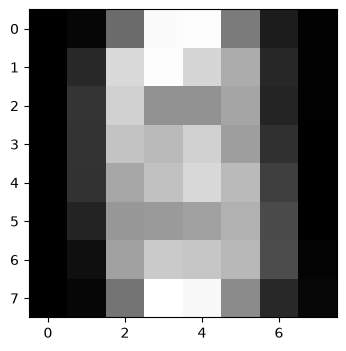

(1347, 65) (269, 65) (450, 65)


In [30]:
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10])
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((8,8)), cmap="gray")
plt.show()
X_train = X_train.astype(np.float32)
X_val   = X_val.astype(np.float32)
X_test  = X_test.astype(np.float32)

X_train -= mean_image
X_val -= mean_image
X_test -= mean_image



X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])



print(X_train.shape, X_val.shape, X_test.shape)

3.4 Реализуйте функции в classifiers/softmax.py




In [31]:
from scripts.classifiers.softmax import softmax_loss_naive
import time

W = np.random.randn(65, 10) * 0.0001
loss, grad = softmax_loss_naive(W, X_train, Y_train, 0.0)

print('loss: %f' % loss)
print('sanity check: %f' % (-np.log(0.1)))

loss: 2.302913
sanity check: 2.302585


3.5 Убедитесь, что вы верно реализовали расчет градиента, сравнив с реализацией численными методами (код приведен ниже).

In [32]:
loss, grad = softmax_loss_naive(W, X_train, Y_train, 0.0)


from scripts.gradient_check import grad_check_sparse
f = lambda w: softmax_loss_naive(w, X_train, Y_train, 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad, 10)


loss, grad = softmax_loss_naive(W, X_train, Y_train, 5e1)
f = lambda w: softmax_loss_naive(w, X_train, Y_train, 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad, 10)

[ 481] numerical:  7.25028171e-04  analytic:  7.25028341e-04  relative error: 1.177e-07
[ 430] numerical:  5.56662704e-01  analytic:  5.56662703e-01  relative error: 5.076e-11
[ 470] numerical:  3.12411439e-03  analytic:  3.12411445e-03  relative error: 1.020e-08
[ 237] numerical: -1.74920793e-03  analytic: -1.74920809e-03  relative error: 4.471e-08
[ 224] numerical: -1.65186744e-01  analytic: -1.65186744e-01  relative error: 2.188e-10
[ 434] numerical: -5.27676436e-01  analytic: -5.27676436e-01  relative error: 4.482e-11
[ 289] numerical: -3.10174295e-01  analytic: -3.10174295e-01  relative error: 4.686e-10
[ 142] numerical:  1.29965988e-01  analytic:  1.29965987e-01  relative error: 5.954e-10
[ 615] numerical:  4.37177911e-01  analytic:  4.37177911e-01  relative error: 4.523e-11
[ 189] numerical: -2.56612515e-01  analytic: -2.56612514e-01  relative error: 4.502e-10
[ 290] numerical: -1.47895675e-01  analytic: -1.47895675e-01  relative error: 1.053e-09
[ 494] numerical: -3.11542152e-0

3.6 Сравните softmax_loss_naive и softmax_loss_vectorized реализации

In [33]:
import time

tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_train, Y_train, 0.000005)
toc = time.time()
print('naive loss: %e computed in %fs' % (loss_naive, toc - tic))

from scripts.classifiers.softmax import softmax_loss_vectorized
tic = time.time()
loss_vectorized, grad_vectorized = softmax_loss_vectorized(W, X_train, Y_train, 0.000005)
toc = time.time()
print('vectorized loss: %e computed in %fs' % (loss_vectorized, toc - tic))


grad_difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('Loss difference: %f' % np.abs(loss_naive - loss_vectorized))
print('Gradient difference: %f' % grad_difference)

naive loss: 2.302913e+00 computed in 0.031421s
vectorized loss: 2.302913e+00 computed in 0.000620s
Loss difference: 0.000000
Gradient difference: 0.000000


3.7 Реализуйте стохастический градиентный спуск в /classifiers/linear_classifier.py . Реализуйте методы train() и predict() и запустите следующий код

3.8 Обучите Softmax-классификатор и оцените accuracy на тестовой выборке.

In [34]:
from scripts.classifiers.linear_classifier import Softmax

softmax = Softmax()

tic = time.time()
loss_hist = softmax.train(
    X_train, Y_train,
    learning_rate=1e-2,
    reg=1e-5,
    num_iters=1500,
    batch_size=200,
    verbose=True
)
toc = time.time()
print('That took %fs' % (toc - tic))

y_train_pred = softmax.predict(X_train)
print('training accuracy: %f' % (np.mean(Y_train == y_train_pred), ))

y_val_pred = softmax.predict(X_val)
print('validation accuracy: %f' % (np.mean(Y_val == y_val_pred), ))

iteration 0 / 1500: loss 2.304320
iteration 100 / 1500: loss 0.184506
iteration 200 / 1500: loss 0.134253
iteration 300 / 1500: loss 0.077167
iteration 400 / 1500: loss 0.096817
iteration 500 / 1500: loss 0.066375
iteration 600 / 1500: loss 0.041590
iteration 700 / 1500: loss 0.089433
iteration 800 / 1500: loss 0.060575
iteration 900 / 1500: loss 0.042036
iteration 1000 / 1500: loss 0.033932
iteration 1100 / 1500: loss 0.052727
iteration 1200 / 1500: loss 0.052511
iteration 1300 / 1500: loss 0.026910
iteration 1400 / 1500: loss 0.030495
That took 0.115687s
training accuracy: 0.997773
validation accuracy: 0.996283


In [35]:
y_test_pred = softmax.predict(X_test)
test_accuracy = np.mean(Y_test == y_test_pred)
print('softmax on raw pixels final test set accuracy: %f' % test_accuracy)

softmax on raw pixels final test set accuracy: 0.960000


3.9 С помощью кросс-валидации выберите значения параметров скорости обучения и регуляризации. В кросс-валидации используйте обучающую и валидационную выборки. Оцените accuracy на тестовой выборке.

In [36]:
learning_rates = [1e-7, 5e-5]
regularization_strengths = [2.5e4, 5e4]


In [38]:
best_val = -1
best_softmax = None

for lr in learning_rates:
    for reg in regularization_strengths:
        softmax = Softmax()
        softmax.train(X_train, Y_train, learning_rate=lr, reg=reg,
                      num_iters=1500, batch_size=200, verbose=False)
        
        y_train_pred = softmax.predict(X_train)
        train_acc = np.mean(Y_train == y_train_pred)
        
        y_val_pred = softmax.predict(X_val)
        val_acc = np.mean(Y_val == y_val_pred)
        
        if val_acc > best_val:
            best_val = val_acc
            best_softmax = softmax

y_test_pred = best_softmax.predict(X_test)
test_acc = np.mean(Y_test == y_test_pred)
print('best validation accuracy: %f' % best_val)
print('test accuracy: %f' % test_acc)

best validation accuracy: 0.873606
test accuracy: 0.857778


3.10 Сделайте выводы по третьей части задания

In [53]:
print("""Реализованы обычная и векторизованная версии функции потерь Softmax и её градиента. Начальное значение функции потерь составило 2,302913, что близко к ожидаемому значению 2,302585. При численной проверке максимальная относительная ошибка градиента составила около 0,00000012. Обе реализации дали одинаковые результаты с точностью до шести знаков после запятой. В проведённом замере векторизованная версия оказалась примерно в 51 раз быстрее.

При скорости обучения 0,01 и коэффициенте регуляризации 0,00001 модель достигла точности 96,00% на тестовой выборке. Модель, выбранная при переборе гиперпараметров, показала 85,78% на тесте. Перебор в заданном диапазоне не улучшил результат. Отдельная валидационная выборка для Softmax не была сформирована, поэтому полученные валидационные оценки нельзя считать независимыми.""")

Реализованы обычная и векторизованная версии функции потерь Softmax и её градиента. Начальное значение функции потерь составило 2,302913, что близко к ожидаемому значению 2,302585. При численной проверке максимальная относительная ошибка градиента составила около 0,00000012. Обе реализации дали одинаковые результаты с точностью до шести знаков после запятой. В проведённом замере векторизованная версия оказалась примерно в 51 раз быстрее.

При скорости обучения 0,01 и коэффициенте регуляризации 0,00001 модель достигла точности 96,00% на тестовой выборке. Модель, выбранная при переборе гиперпараметров, показала 85,78% на тесте. Перебор в заданном диапазоне не улучшил результат. Отдельная валидационная выборка для Softmax не была сформирована, поэтому полученные валидационные оценки нельзя считать независимыми.
